Exploring a graph.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn

from query import *
from summary import *


vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


{'UnnamedPipeObject': '2', 'MemoryObject': '197', 'Event': '11526', 'FileObject': '63', 'SrcSinkObject': '92', 'Principal': '2', 'Subject': '35'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

[{'Event': 11526,
  'FileObject': 63,
  'MemoryObject': 197,
  'Principal': 2,
  'SrcSinkObject': 92,
  'Subject': 35,
  'UnnamedPipeObject': 2}]

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertexSummary()
print (vertices)

Vertex types/counts:
{'UnnamedPipeObject': {'count': 2, 'in': {'predicateObject': 10}, 'out': {}}, 'MemoryObject': {'count': 197, 'in': {'predicateObject2': 101, 'predicateObject': 127}, 'out': {}}, 'Event': {'count': 11526, 'in': {}, 'out': {'predicateObject2': 101, 'subject': 11526, 'predicateObject': 11526}}, 'FileObject': {'count': 63, 'in': {'predicateObject': 389}, 'out': {}}, 'SrcSinkObject': {'count': 92, 'in': {'predicateObject': 10988}, 'out': {}}, 'Principal': {'count': 2, 'in': {'localPrincipal': 35}, 'out': {}}, 'Subject': {'count': 35, 'in': {'parentSubject': 13, 'subject': 11526, 'predicateObject': 12}, 'out': {'localPrincipal': 35, 'parentSubject': 13}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdgeSummary()
print (edges)

Edge types/counts:
{'predicateObject2': {'count': 101, 'in': {'MemoryObject': 101}, 'out': {'Event': 101}}, 'localPrincipal': {'count': 35, 'in': {'Principal': 35}, 'out': {'Subject': 35}}, 'parentSubject': {'count': 13, 'in': {'Subject': 13}, 'out': {'Subject': 13}}, 'subject': {'count': 11526, 'in': {'Subject': 11526}, 'out': {'Event': 11526}}, 'predicateObject': {'count': 11526, 'in': {'UnnamedPipeObject': 10, 'MemoryObject': 127, 'FileObject': 389, 'SrcSinkObject': 10988, 'Subject': 12}, 'out': {'Event': 11526}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{predicateObject[10]}
 -> 
UnnamedPipeObject[2]
 -> 
{}

{predicateObject2[101],
predicateObject[127]}
 -> 
MemoryObject[197]
 -> 
{}

{}
 -> 
Event[11526]
 -> 
{predicateObject2[101],
subject[11526],
predicateObject[11526]}

{predicateObject[389]}
 -> 
FileObject[63]
 -> 
{}

{predicateObject[10988]}
 -> 
SrcSinkObject[92]
 -> 
{}

{localPrincipal[35]}
 -> 
Principal[2]
 -> 
{}

{parentSubject[13],
subject[11526],
predicateObject[12]}
 -> 
Subject[35]
 -> 
{localPrincipal[35],
parentSubject[13]}



How about for edges?

In [8]:
printSummary(edges)

{MemoryObject[101]}
 -> 
predicateObject2[101]
 -> 
{Event[101]}

{Principal[35]}
 -> 
localPrincipal[35]
 -> 
{Subject[35]}

{Subject[13]}
 -> 
parentSubject[13]
 -> 
{Subject[13]}

{Subject[11526]}
 -> 
subject[11526]
 -> 
{Event[11526]}

{UnnamedPipeObject[10],
MemoryObject[127],
FileObject[389],
SrcSinkObject[10988],
Subject[12]}
 -> 
predicateObject[11526]
 -> 
{Event[11526]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [9]:
G = nx.DiGraph()


In [10]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [11]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [12]:
nx.is_bipartite(G)

True

In [13]:
from networkx.algorithms import bipartite
bottom_nodes, top_nodes = bipartite.sets(G)
bottom_nodes,top_nodes

({'Event',
  'FileObject',
  'MemoryObject',
  'Principal',
  'SrcSinkObject',
  'Subject',
  'UnnamedPipeObject'},
 {'localPrincipal',
  'parentSubject',
  'predicateObject',
  'predicateObject2',
  'subject'})

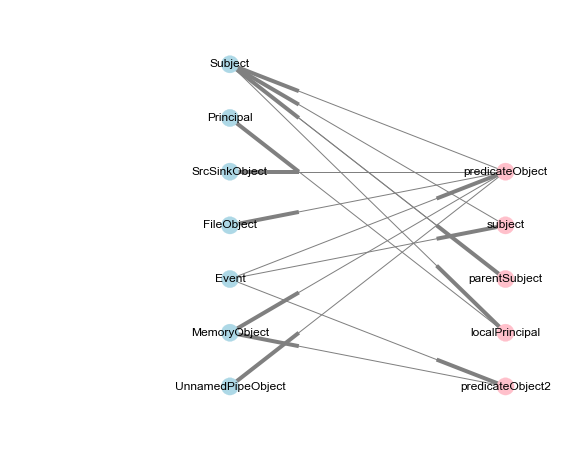

In [15]:
def showBiGraph(G):
    colors = ['lightblue' if d['bipartite']==0 else 'pink' for x,d in G.nodes(data=True)]
    positions = {}
    i = 1
    j = 1
    for x,d in G.nodes(data=True):
        if d['bipartite'] == 0:
            positions[x] = (3,i)
            i = i + 1
        else:
            positions[x] = (7,j)
            j = j + 1
    height = max(i,j)
    fig = plt.figure(figsize=(10,height))
    plt.gca().set_axis_off()   
    plt.gca().set_xlim([-0.05, height+0.05])    # add a little space around the plot
    plt.gca().set_ylim([-0.05, height+0.05])

    nx.draw_networkx(G,pos=positions,
                   with_labels=True,node_color=colors,edge_color='gray')

    _ = plt.show()

showBiGraph(G)

Consider the edge labels into and out of each node type and abstract them as +, *, 1, or ?

In [47]:
summarizeIncidences('Event')

{'in': {},
 'out': {'predicateObject': '1', 'predicateObject2': '?', 'subject': '1'}}

In [20]:

schema = inferSchema(vertices.keys())
schema

{'Event': {'in': {},
  'out': {'predicateObject': '1', 'predicateObject2': '?', 'subject': '1'}},
 'FileObject': {'in': {'predicateObject': '+'}, 'out': {}},
 'MemoryObject': {'in': {'predicateObject': '*', 'predicateObject2': '*'},
  'out': {}},
 'Principal': {'in': {'localPrincipal': '+'}, 'out': {}},
 'SrcSinkObject': {'in': {'predicateObject': '*'}, 'out': {}},
 'Subject': {'in': {'parentSubject': '*',
   'predicateObject': '*',
   'subject': '+'},
  'out': {'localPrincipal': '1', 'parentSubject': '?'}},
 'UnnamedPipeObject': {'in': {'predicateObject': '+'}, 'out': {}}}

A _rigid path_ is a path that follows only edges with multiplicity <= 1.  Edges can be traversed in either direction but should not be traversed twice.  Rigid paths are useful for exploring because it does no harm to follow them.

In [21]:
def multLeq1(edges):
    return {label for label in edges.keys() if edges[label]== '1' or edges[label] == '?'}

def schemaMultLeq1(schema):
    return {label : {'in': multLeq1(schema[label]['in']), 'out':multLeq1(schema[label]['out'])}
             for label in schema.keys()}
            
schemaMultLeq1(schema)
            

{'Event': {'in': set(),
  'out': {'predicateObject', 'predicateObject2', 'subject'}},
 'FileObject': {'in': set(), 'out': set()},
 'MemoryObject': {'in': set(), 'out': set()},
 'Principal': {'in': set(), 'out': set()},
 'SrcSinkObject': {'in': set(), 'out': set()},
 'Subject': {'in': set(), 'out': {'localPrincipal', 'parentSubject'}},
 'UnnamedPipeObject': {'in': set(), 'out': set()}}